In [6]:
from google.colab import files
uploaded = files.upload()

Saving payments.csv to payments.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

loans = pd.read_csv("loans.csv")
customers = pd.read_csv("customers.csv")
payments = pd.read_csv("payments.csv")
accounts = pd.read_csv("accounts.csv")
history = pd.read_csv("history.csv")

print("All datasets loaded successfully!")
print("Loans:", loans.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)
print("Accounts:", accounts.shape)
print("History:", history.shape)

All datasets loaded successfully!
Loans: (650, 6)
Customers: (500, 4)
Payments: (3908, 8)
Accounts: (500, 3)
History: (500, 3)


In [8]:

print("LOANS")
display(loans.head())

print("CUSTOMERS")
display(customers.head())

print("PAYMENTS")
display(payments.head())

print("ACCOUNTS")
display(accounts.head())

print("HISTORY")
display(history.head())

LOANS


,loan_id,customer_id,loan_type,loan_amount,tenure_months,interest_rate
0,L00001,C00189,Vehicle Loan,15911.0,84,16.59
1,L00002,C00424,Home Loan,173897.0,24,8.47
2,L00003,C00266,Education Loan,44314.0,36,19.73
3,L00004,C00103,Vehicle Loan,34097.0,24,21.36
4,L00005,C00297,Vehicle Loan,205252.0,12,22.69


CUSTOMERS


,customer_id,income_band,occupation,region
0,C00001,Upper-Middle,Agriculture,Central
1,C00002,Lower-Middle,Salaried,West
2,C00003,High,Business,West
3,C00004,Upper-Middle,Business,South
4,C00005,Low,Salaried,East


PAYMENTS


,payment_id,loan_id,customer_id,due_date,paid_date,amount_due,amount_paid,payment_status
0,P0000001,L00001,C00189,2025-07-07,2025-07-05,500.0,495.71,Paid
1,P0000002,L00001,C00189,2025-08-07,2025-08-06,500.0,472.96,Paid
2,P0000003,L00001,C00189,2025-09-07,2025-09-05,500.0,490.19,Paid
3,P0000004,L00001,C00189,2025-10-07,2025-10-04,500.0,466.50,Paid
4,P0000005,L00001,C00189,2025-11-07,2025-11-04,500.0,428.87,Paid


ACCOUNTS


,customer_id,balance_band,relationship_months
0,C00001,High,19
1,C00002,Medium,127
2,C00003,Low,63
3,C00004,Medium,31
4,C00005,Medium,85


HISTORY


,customer_id,past_delay_count,restructured_flag
0,C00001,0,0
1,C00002,1,0
2,C00003,3,0
3,C00004,0,0
4,C00005,0,0


In [9]:
datasets = {
    "loans": loans,
    "customers": customers,
    "payments": payments,
    "accounts": accounts,
    "history": history
}

for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print("Data types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())


--- LOANS ---
Data types:
loan_id           object
customer_id       object
loan_type         object
loan_amount      float64
tenure_months      int64
interest_rate    float64
dtype: object

Missing values:
loan_id          0
customer_id      0
loan_type        0
loan_amount      0
tenure_months    0
interest_rate    0
dtype: int64

Duplicate rows: 0

--- CUSTOMERS ---
Data types:
customer_id    object
income_band    object
occupation     object
region         object
dtype: object

Missing values:
customer_id     0
income_band    28
occupation      0
region          0
dtype: int64

Duplicate rows: 0

--- PAYMENTS ---
Data types:
payment_id         object
loan_id            object
customer_id        object
due_date           object
paid_date          object
amount_due        float64
amount_paid       float64
payment_status     object
dtype: object

Missing values:
payment_id          0
loan_id             0
customer_id         0
due_date            0
paid_date         184
amount_due   

In [10]:
loans_clean = loans.copy()
customers_clean = customers.copy()
payments_clean = payments.copy()
accounts_clean = accounts.copy()
history_clean = history.copy()

# 1. Standardize loan type labels
loans_clean["loan_type"] = (
    loans_clean["loan_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# 2. Fill missing income bands
customers_clean["income_band"] = (
    customers_clean["income_band"]
    .fillna("Unknown")
)

# 3. Remove exact duplicate payment rows
payments_clean = payments_clean.drop_duplicates().copy()

# 4. Convert payment dates
for col in ["due_date", "paid_date"]:
    payments_clean[col] = pd.to_datetime(
        payments_clean[col],
        errors="coerce"
    )

# 5. Convert loan amount to numeric
loans_clean["loan_amount"] = pd.to_numeric(
    loans_clean["loan_amount"],
    errors="coerce"
)

print("Data cleaning completed!")
print("Cleaned loans:", loans_clean.shape)
print("Cleaned customers:", customers_clean.shape)
print("Cleaned payments:", payments_clean.shape)

Data cleaning completed!
Cleaned loans: (650, 6)
Cleaned customers: (500, 4)
Cleaned payments: (3900, 8)


In [11]:
payments_clean["delay_days"] = (
    payments_clean["paid_date"]
    - payments_clean["due_date"]
).dt.days

payments_clean["late_payment"] = (
    payments_clean["delay_days"] > 0
).astype("Int64")

payments_clean["unpaid_payment"] = (
    payments_clean["payment_status"]
    .str.strip()
    .str.lower()
    .eq("missed")
    .astype(int)
)

display(
    payments_clean[
        ["loan_id", "due_date", "paid_date",
         "payment_status", "delay_days",
         "late_payment", "unpaid_payment"]
    ].head(10)
)

,loan_id,due_date,paid_date,payment_status,delay_days,late_payment,unpaid_payment
0,L00001,2025-07-07,2025-07-05,Paid,-2.0,0,0
1,L00001,2025-08-07,2025-08-06,Paid,-1.0,0,0
2,L00001,2025-09-07,2025-09-05,Paid,-2.0,0,0
3,L00001,2025-10-07,2025-10-04,Paid,-3.0,0,0
4,L00001,2025-11-07,2025-11-04,Paid,-3.0,0,0
5,L00001,2025-12-07,2025-12-07,Paid,0.0,0,0
6,L00002,2025-03-10,2025-04-10,Late,31.0,1,0
7,L00002,2025-04-10,2025-04-10,Paid,0.0,0,0
8,L00002,2025-05-10,2025-05-07,Paid,-3.0,0,0
9,L00002,2025-06-10,2025-07-20,Late,40.0,1,0


In [12]:
analysis_df = (
    payments_clean
    .merge(
        loans_clean,
        on=["loan_id", "customer_id"],
        how="left",
        validate="many_to_one"
    )
    .merge(
        customers_clean,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        accounts_clean,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        history_clean,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

print("Combined dataset shape:", analysis_df.shape)
display(analysis_df.head())

Combined dataset shape: (3900, 22)


,payment_id,loan_id,customer_id,due_date,paid_date,amount_due,amount_paid,payment_status,delay_days,late_payment,...,loan_amount,tenure_months,interest_rate,income_band,occupation,region,balance_band,relationship_months,past_delay_count,restructured_flag
0,P0000001,L00001,C00189,2025-07-07,2025-07-05,500.0,495.71,Paid,-2.0,0,...,15911.0,84,16.59,Upper-Middle,Self-employed,North,Medium,80,1,0
1,P0000002,L00001,C00189,2025-08-07,2025-08-06,500.0,472.96,Paid,-1.0,0,...,15911.0,84,16.59,Upper-Middle,Self-employed,North,Medium,80,1,0
2,P0000003,L00001,C00189,2025-09-07,2025-09-05,500.0,490.19,Paid,-2.0,0,...,15911.0,84,16.59,Upper-Middle,Self-employed,North,Medium,80,1,0
3,P0000004,L00001,C00189,2025-10-07,2025-10-04,500.0,466.50,Paid,-3.0,0,...,15911.0,84,16.59,Upper-Middle,Self-employed,North,Medium,80,1,0
4,P0000005,L00001,C00189,2025-11-07,2025-11-04,500.0,428.87,Paid,-3.0,0,...,15911.0,84,16.59,Upper-Middle,Self-employed,North,Medium,80,1,0


,loan_type,delay_rate_percent
0,education loan,20.32
1,home loan,23.69
2,personal loan,21.22
3,vehicle loan,23.1


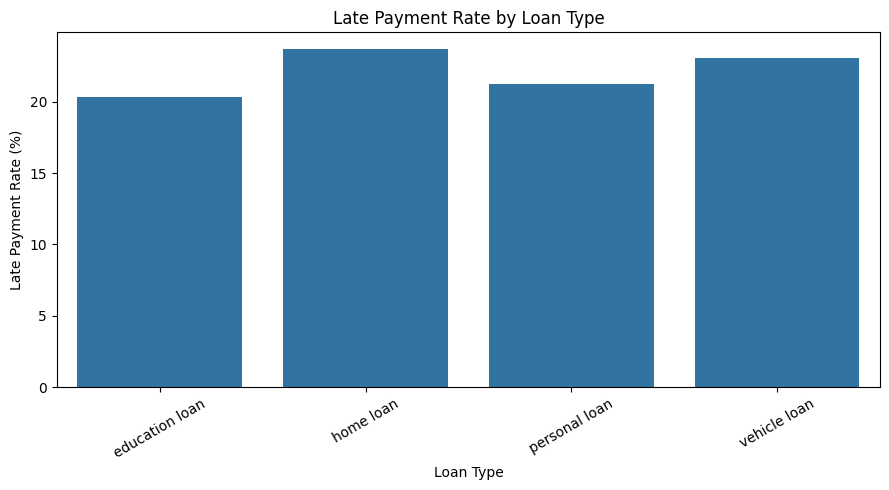

In [13]:
delay_by_type = (
    analysis_df.groupby("loan_type")["late_payment"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="delay_rate_percent")
)

display(delay_by_type)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=delay_by_type,
    x="loan_type",
    y="delay_rate_percent"
)

plt.title("Late Payment Rate by Loan Type")
plt.xlabel("Loan Type")
plt.ylabel("Late Payment Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,tenure_months,total_payments,late_payment_rate,unpaid_rate
0,6,174,24.71,2.30
1,12,384,21.88,2.86
2,18,354,20.34,4.52
3,24,570,22.28,4.74
4,36,894,20.02,5.48
5,48,450,24.89,4.89
6,60,456,26.54,4.82
7,84,216,19.91,5.09
8,120,258,20.93,6.20
9,180,144,19.44,2.08


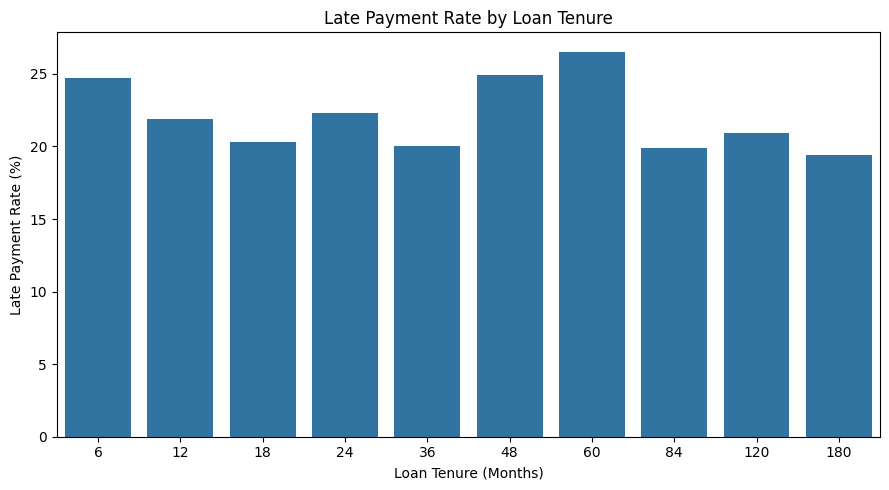

In [14]:
tenure_analysis = (
    analysis_df.groupby("tenure_months")
    .agg(
        total_payments=("payment_id", "count"),
        late_payment_rate=("late_payment", "mean"),
        unpaid_rate=("unpaid_payment", "mean")
    )
    .reset_index()
)

tenure_analysis["late_payment_rate"] *= 100
tenure_analysis["unpaid_rate"] *= 100

display(tenure_analysis.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=tenure_analysis,
    x="tenure_months",
    y="late_payment_rate"
)
plt.title("Late Payment Rate by Loan Tenure")
plt.xlabel("Loan Tenure (Months)")
plt.ylabel("Late Payment Rate (%)")
plt.tight_layout()
plt.show()

,income_band,total_payments,late_payment_rate,unpaid_rate
0,High,426,15.73,5.40
1,Low,1086,28.45,3.31
2,Lower-Middle,1290,23.33,4.88
3,Unknown,264,15.91,5.30
4,Upper-Middle,834,17.27,5.40


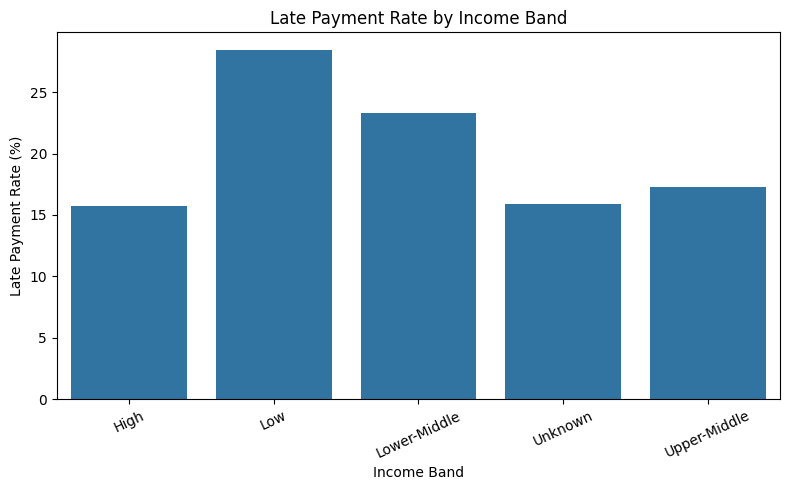

In [15]:
income_analysis = (
    analysis_df.groupby("income_band", dropna=False)
    .agg(
        total_payments=("payment_id", "count"),
        late_payment_rate=("late_payment", "mean"),
        unpaid_rate=("unpaid_payment", "mean")
    )
    .reset_index()
)

income_analysis["late_payment_rate"] *= 100
income_analysis["unpaid_rate"] *= 100

display(income_analysis.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=income_analysis,
    x="income_band",
    y="late_payment_rate"
)
plt.title("Late Payment Rate by Income Band")
plt.xlabel("Income Band")
plt.ylabel("Late Payment Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

,past_delay_count,total_payments,late_payment_rate
0,0,2010,19.55
1,1,1290,22.79
2,2,438,29.91
3,3,144,24.31
4,4,18,55.56


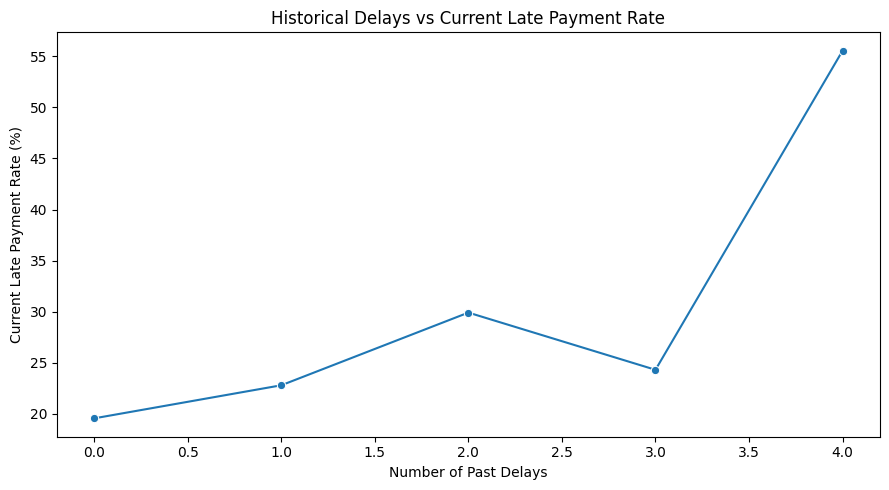

In [16]:
history_analysis = (
    analysis_df.groupby("past_delay_count")
    .agg(
        total_payments=("payment_id", "count"),
        late_payment_rate=("late_payment", "mean")
    )
    .reset_index()
)

history_analysis["late_payment_rate"] *= 100

display(history_analysis.round(2))

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=history_analysis,
    x="past_delay_count",
    y="late_payment_rate",
    marker="o"
)
plt.title("Historical Delays vs Current Late Payment Rate")
plt.xlabel("Number of Past Delays")
plt.ylabel("Current Late Payment Rate (%)")
plt.tight_layout()
plt.show()

,region,total_payments,late_payment_rate,unpaid_rate
0,Central,726,24.24,3.99
1,East,744,23.79,5.11
2,North,756,21.16,4.89
3,South,852,21.36,3.99
4,West,822,20.44,5.23


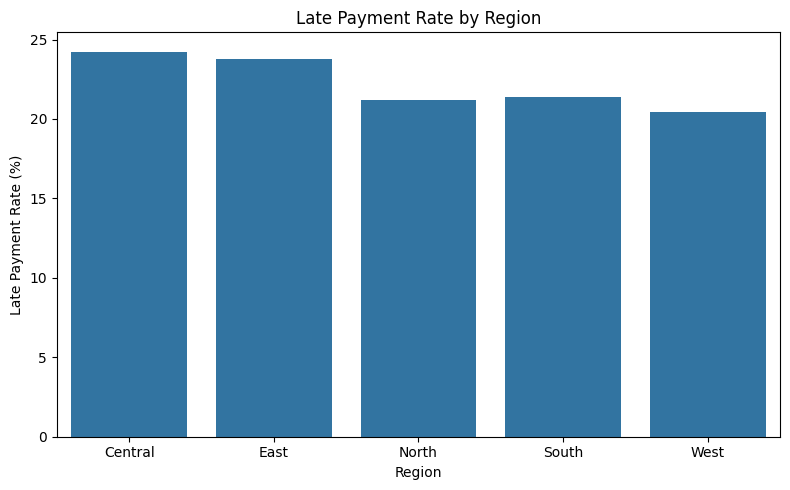

In [17]:
region_analysis = (
    analysis_df.groupby("region")
    .agg(
        total_payments=("payment_id", "count"),
        late_payment_rate=("late_payment", "mean"),
        unpaid_rate=("unpaid_payment", "mean")
    )
    .reset_index()
)

region_analysis["late_payment_rate"] *= 100
region_analysis["unpaid_rate"] *= 100

display(region_analysis.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=region_analysis,
    x="region",
    y="late_payment_rate"
)
plt.title("Late Payment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Late Payment Rate (%)")
plt.tight_layout()
plt.show()

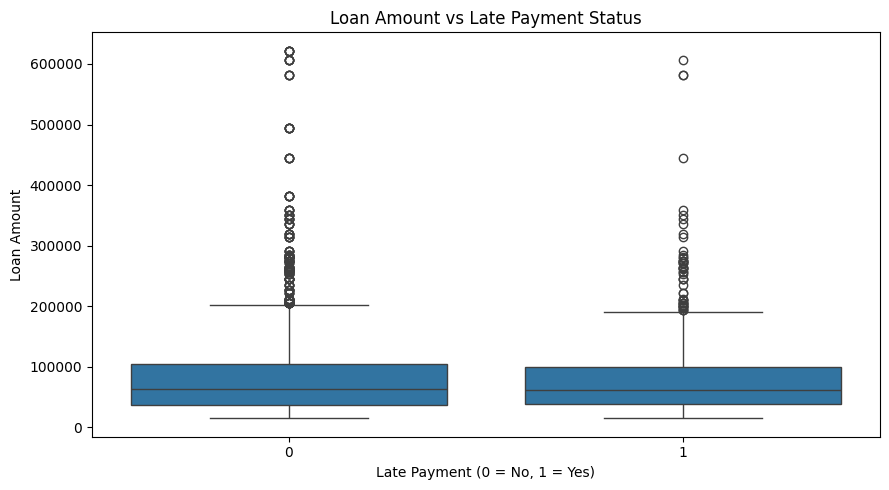

In [18]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=analysis_df,
    x="late_payment",
    y="loan_amount"
)

plt.title("Loan Amount vs Late Payment Status")
plt.xlabel("Late Payment (0 = No, 1 = Yes)")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

In [19]:
Q1 = loans_clean["loan_amount"].quantile(0.25)
Q3 = loans_clean["loan_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = loans_clean[
    (loans_clean["loan_amount"] < lower_limit) |
    (loans_clean["loan_amount"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outliers:", len(outliers))

display(outliers.head(10))

Lower limit: -60695.875
Upper limit: 201375.125
Potential outliers: 38


,loan_id,customer_id,loan_type,loan_amount,tenure_months,interest_rate
4,L00005,C00297,vehicle loan,205252.0,12,22.69
23,L00024,C00124,personal loan,258644.0,6,16.07
32,L00033,C00465,education loan,274732.0,48,12.68
43,L00044,C00397,personal loan,335960.0,120,9.92
55,L00056,C00002,home loan,202917.0,120,16.11
57,L00058,C00076,education loan,359571.0,36,11.21
61,L00062,C00010,vehicle loan,343956.0,24,12.50
66,L00067,C00473,vehicle loan,261606.0,18,20.04
74,L00075,C00212,education loan,351452.0,18,20.34
126,L00127,C00181,vehicle loan,382260.0,18,23.57


In [20]:
selected_features = [
    "loan_amount",
    "tenure_months",
    "interest_rate",
    "past_delay_count",
    "restructured_flag",
    "relationship_months"
]

feature_df = analysis_df[
    selected_features + ["late_payment"]
].copy()

display(feature_df.head())

,loan_amount,tenure_months,interest_rate,past_delay_count,restructured_flag,relationship_months,late_payment
0,15911.0,84,16.59,1,0,80,0
1,15911.0,84,16.59,1,0,80,0
2,15911.0,84,16.59,1,0,80,0
3,15911.0,84,16.59,1,0,80,0
4,15911.0,84,16.59,1,0,80,0


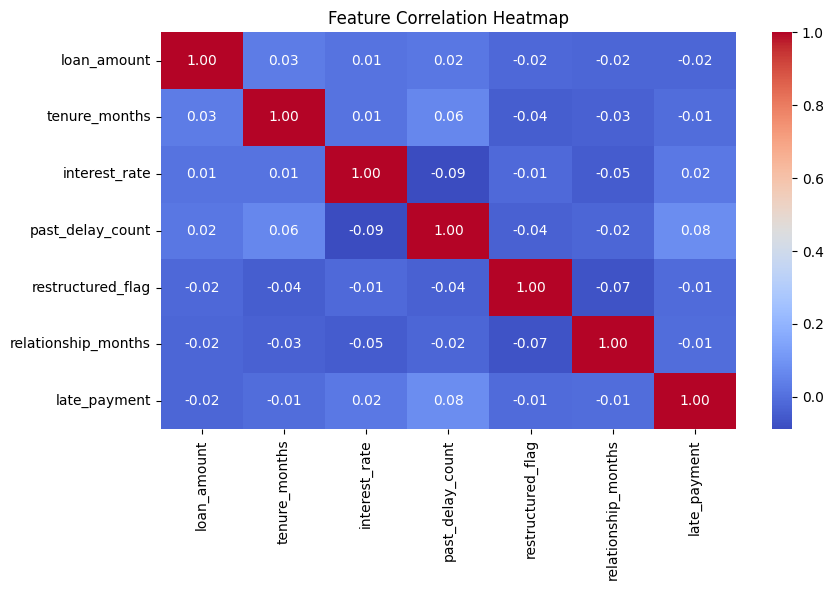

In [21]:
correlation = feature_df.corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import LabelEncoder
import pandas as pd

In [28]:
df = analysis_df.copy()

features = [
    "loan_amount",
    "tenure_months",
    "interest_rate",
    "past_delay_count",
    "relationship_months",
    "restructured_flag"
]

target = "late_payment"

# Keep records with a valid target
df = df.dropna(subset=[target]).copy()

# Convert categorical fields to numeric codes
for col in ["restructured_flag"]:
    df[col] = df[col].astype(str)

X = df[features].copy()
y = df[target].astype(int)

# Fill missing feature values
X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6615384615384615
F1-score: 0.2864864864864865
              precision    recall  f1-score   support

           0       0.79      0.76      0.78       607
           1       0.27      0.31      0.29       173

    accuracy                           0.66       780
   macro avg       0.53      0.53      0.53       780
weighted avg       0.68      0.66      0.67       780



,Feature,Importance
2,interest_rate,0.279949
0,loan_amount,0.274582
4,relationship_months,0.246784
1,tenure_months,0.125230
3,past_delay_count,0.057286
5,restructured_flag,0.016170


<Axes: title={'center': 'Random Forest Feature Importance'}, xlabel='Feature', ylabel='Importance'>

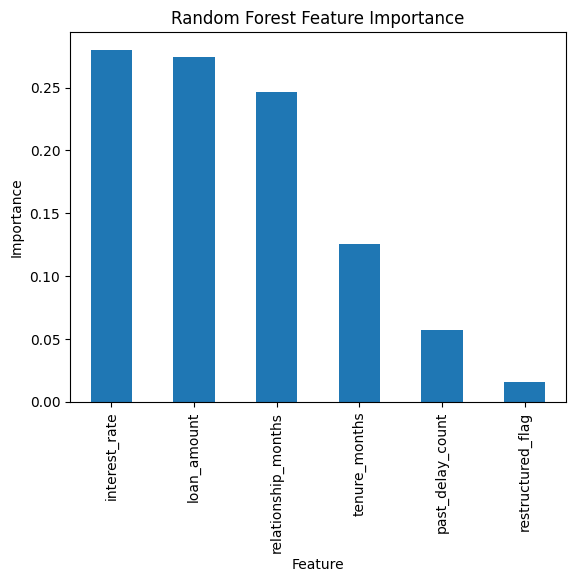

In [30]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    title="Random Forest Feature Importance",
    ylabel="Importance"
)

In [22]:
loans_clean.to_csv("cleaned_loans.csv", index=False)
customers_clean.to_csv("cleaned_customers.csv", index=False)
payments_clean.to_csv("cleaned_payments.csv", index=False)
accounts_clean.to_csv("cleaned_accounts.csv", index=False)
history_clean.to_csv("cleaned_history.csv", index=False)

analysis_df.to_csv("loan_portfolio_analysis.csv", index=False)

print("All cleaned files and the combined dataset are saved.")

All cleaned files and the combined dataset are saved.


In [24]:
from google.colab import files

files.download("loan_portfolio_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

# Overall repayment summary

total_payments = len(analysis_df)
late_payments = analysis_df["late_payment"].sum()
unpaid_payments = analysis_df["unpaid_payment"].sum()

late_rate = analysis_df["late_payment"].mean() * 100
unpaid_rate = analysis_df["unpaid_payment"].mean() * 100

print("LOAN PORTFOLIO SUMMARY")
print("----------------------")
print("Total payment records:", total_payments)
print("Late payment records:", int(late_payments))
print("Unpaid payment records:", int(unpaid_payments))
print(f"Late payment rate: {late_rate:.2f}%")
print(f"Unpaid payment rate: {unpaid_rate:.2f}%")

LOAN PORTFOLIO SUMMARY
----------------------
Total payment records: 3900
Late payment records: 863
Unpaid payment records: 181
Late payment rate: 22.13%
Unpaid payment rate: 4.64%


In [26]:

def delay_summary(column):
    result = (
        analysis_df.groupby(column)["late_payment"]
        .agg(["mean", "count"])
        .reset_index()
    )
    result["delay_rate_percent"] = result["mean"] * 100
    return result.sort_values(
        "delay_rate_percent", ascending=False
    )

for col in ["loan_type", "income_band", "region"]:
    print(f"\nHighest observed delay rates: {col}")
    display(delay_summary(col).head(5).round(2))


Highest observed delay rates: loan_type


,loan_type,mean,count,delay_rate_percent
1,home loan,0.24,612,23.69
3,vehicle loan,0.23,1290,23.1
2,personal loan,0.21,1560,21.22
0,education loan,0.2,438,20.32



Highest observed delay rates: income_band


,income_band,mean,count,delay_rate_percent
1,Low,0.28,1086,28.45
2,Lower-Middle,0.23,1290,23.33
4,Upper-Middle,0.17,834,17.27
3,Unknown,0.16,264,15.91
0,High,0.16,426,15.73



Highest observed delay rates: region


,region,mean,count,delay_rate_percent
0,Central,0.24,726,24.24
1,East,0.24,744,23.79
3,South,0.21,852,21.36
2,North,0.21,756,21.16
4,West,0.2,822,20.44
